In [1]:
from utils.flow_utils import OpticalFlowEstimator, compute_scene_flow_world, scene_flow_to_optical_flow, load_image
from utils.flow_viz import flow_to_image
import torch
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

xFormers not available
xFormers not available


In [2]:
data_root = "/network-volume/nhphuc/dataset"
image1_path = f"{data_root}/endonerf/pulling_soft_tissues/images/frame-000046.color.png"
image2_path = f"{data_root}/endonerf/pulling_soft_tissues/images/frame-000047.color.png"
depth1_path = f"{data_root}/endonerf/pulling_soft_tissues/fs_depth/frame-000046.color.npy"
depth2_path = f"{data_root}/endonerf/pulling_soft_tissues/fs_depth/frame-000047.color.npy"
mask1_path = f"{data_root}/endonerf/pulling_soft_tissues/masks/frame-000046.mask.png"
mask2_path = f"{data_root}/endonerf/pulling_soft_tissues/masks/frame-000047.mask.png"
intrinsic_path = f"{data_root}/endonerf/pulling_soft_tissues/K.npy"

In [3]:
flownet = OpticalFlowEstimator("flowseek")

/network-volume/nhphuc/EndoFlow/flowseek/flowseek.py:42: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  self.dav2.load_state_dict(torch.load(f'weights/depth_anything_v2_%s.pt

In [4]:
def load_mask(mask_path):
    mask = Image.open(mask_path).convert("L")
    mask = np.array(mask).astype(np.float32) / 255.0
    if "stereomis" not in mask_path:
        mask = 1.0 - mask
    mask = mask > 0
    return torch.from_numpy(mask).cuda().bool()

image1 = load_image(image1_path)
image2 = load_image(image2_path)
depth1 = torch.from_numpy(np.load(depth1_path)).cuda().float()
depth2 = torch.from_numpy(np.load(depth2_path)).cuda().float()
mask1 = load_mask(mask1_path)
mask2 = load_mask(mask2_path)
K1 = torch.from_numpy(np.load(intrinsic_path)).cuda().float()
K2 = torch.from_numpy(np.load(intrinsic_path)).cuda().float()
E1 = torch.eye(4).cuda().float()
E2 = torch.eye(4).cuda().float()

In [5]:
forward_flow = flownet.forward(image1, image2)
backward_flow = flownet.forward(image2, image1)

/root/miniconda3/envs/EndoFlow/lib/python3.8/site-packages/torch/functional.py:513: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3609.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


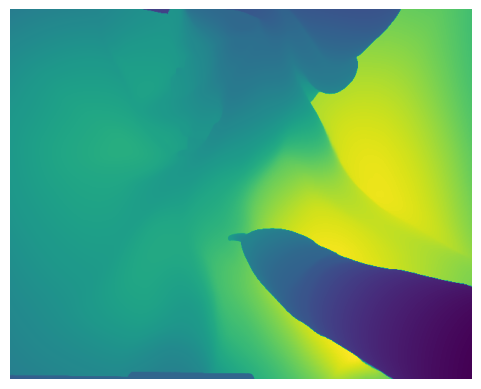

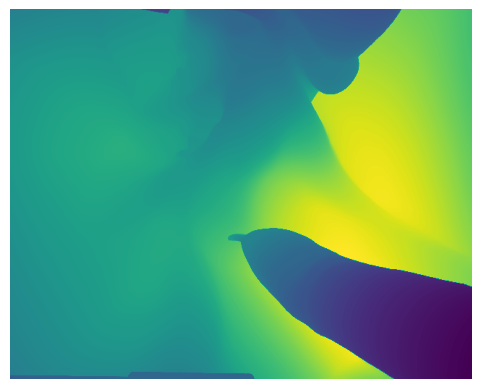

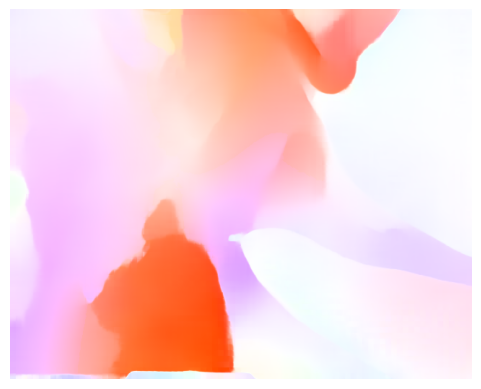

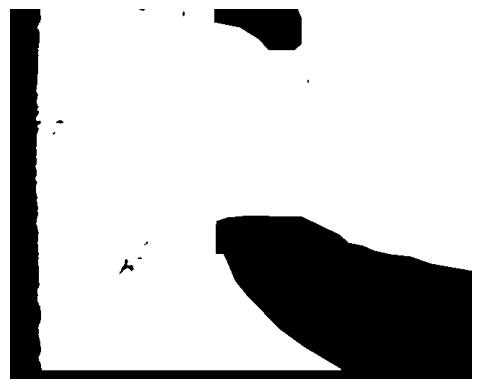

In [6]:
plt.imshow(depth1.cpu().numpy())
plt.axis('off')
plt.show()

plt.imshow(depth2.cpu().numpy())
plt.axis('off')
plt.show()

plt.imshow(flow_to_image(forward_flow.cpu().numpy()))
plt.axis('off')
plt.show()

plt.imshow(mask1.cpu().numpy(), cmap="gray")
plt.axis('off')
plt.show()

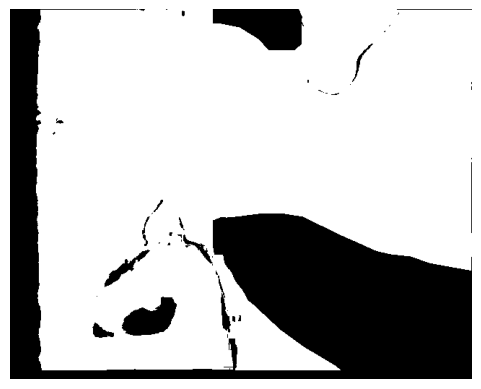

In [7]:
scene_flow, scene_valid_mask = compute_scene_flow_world(
    depth1[None, None],
    depth2[None, None],
    forward_flow.permute(2, 0, 1)[None],
    backward_flow.permute(2, 0, 1)[None],
    mask1[None, None],
    mask2[None, None],
    K1[None],
    K2[None],
    E1[None],
    E2[None],
)

plt.imshow(scene_valid_mask[0, 0].cpu().numpy(), cmap='gray')
plt.axis('off')
plt.show()

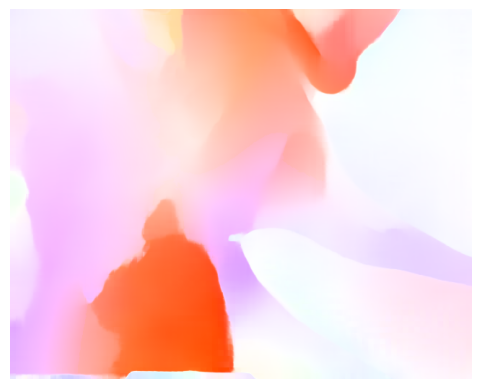

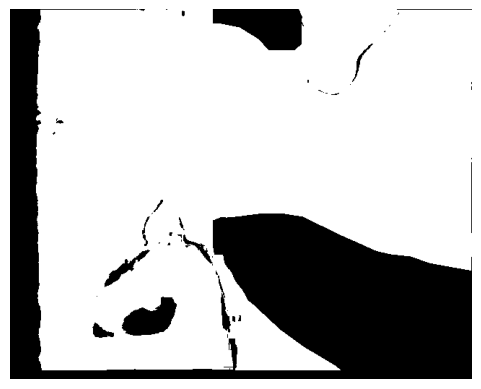

In [8]:
optical_flow, optical_valid_mask = scene_flow_to_optical_flow(
    scene_flow,
    depth1[None, None],
    K1[None],
    K2[None],
    E1[None],
    E2[None],
    visible=scene_valid_mask,
)

plt.imshow(flow_to_image(optical_flow[0].permute(1, 2, 0).cpu().numpy()))
plt.axis('off')
plt.show()

plt.imshow(optical_valid_mask[0, 0].cpu().numpy(), cmap="gray")
plt.axis('off')
plt.show()